# 01 — Exploration des Données (LOL-v2 & ExDark)
**Projet NightVision Gen — Amélioration de scènes nocturnes par diffusion conditionnelle**

Ce notebook explore les deux jeux de données du projet :
1. **LOL-v2 (Real_captured)** : paires image sombre / image de référence bien exposée pour l'entraînement et l'évaluation de la restauration.
2. **ExDark** : images nocturnes en scènes réelles annotées par classe pour l'évaluation de la détection d'objets.

---
### Objectifs :
- Vérifier l'accès et les chemins des datasets.
- Analyser la répartition des classes et les conditions d'éclairage.
- Visualiser des paires sombre/référence de LOL-v2.
- Vérifier les partitions Train / Validation / Test (100 paires de test LOL-v2 strictement réservées).

In [1]:
# 1. Imports et initialisation de l'environnement
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Ajout du dossier source au PATH
sys.path.append(str(Path("..").resolve() / "src"))

from nightvision.utils.config import load_config
from nightvision.utils.reproducibility import set_seed
from nightvision.data.split_manager import LOLv2SplitManager, ExDarkManager
from nightvision.data.dataset import SyntheticPairDataset

set_seed(42)
print("✅ Environnement initialisé avec succès.")

✅ Environnement initialisé avec succès.


### 2. Configuration et Découverte des Données

In [2]:
# Chargement de la configuration des données
config_path = Path("../configs/data.yaml")
if config_path.exists():
    cfg = load_config(config_path)
    print("Configuration chargée depuis :", config_path)
else:
    print("Fichier data.yaml non trouvé, utilisation des paramètres par défaut.")
    cfg = {"datasets": {"lol_v2": {"root_dir": "../data/raw/LOLv2"}, "exdark": {"root_dir": "../data/raw/ExDark"}}}

lol_root = Path(cfg["datasets"]["lol_v2"]["root_dir"])
exdark_root = Path(cfg["datasets"]["exdark"]["root_dir"])
print(f"Chemin LOL-v2 : {lol_root}")
print(f"Chemin ExDark : {exdark_root}")

Configuration chargée depuis : ..\configs\data.yaml
Chemin LOL-v2 : data\raw\LOLv2
Chemin ExDark : data\raw\ExDark


### 3. Analyse des Partitions LOL-v2
Vérification des 100 paires de test et constitution de la validation sans fuite de données.

In [3]:
lol_mgr = LOLv2SplitManager(root_dir=lol_root, val_ratio=0.15, seed=42)
splits = lol_mgr.create_splits()

print(f"Train pairs : {len(splits['train'])}")
print(f"Validation pairs : {len(splits['val'])}")
print(f"Test pairs : {len(splits['test'])}")

if len(splits['train']) == 0:
    print("ℹ️ LOL-v2 non encore téléchargé en local. Démonstration via SyntheticPairDataset.")
    demo_ds = SyntheticPairDataset(length=6, image_size=128)
else:
    demo_ds = None

Low-light directory does not exist: data\raw\LOLv2\Real_captured\Train\Low
Low-light directory does not exist: data\raw\LOLv2\Real_captured\Test\Low
Low-light directory does not exist: data\raw\LOLv2\Low


Train pairs : 0
Validation pairs : 0
Test pairs : 0
ℹ️ LOL-v2 non encore téléchargé en local. Démonstration via SyntheticPairDataset.


### 4. Visualisation des Paires Sombre / Référence (LOL-v2)

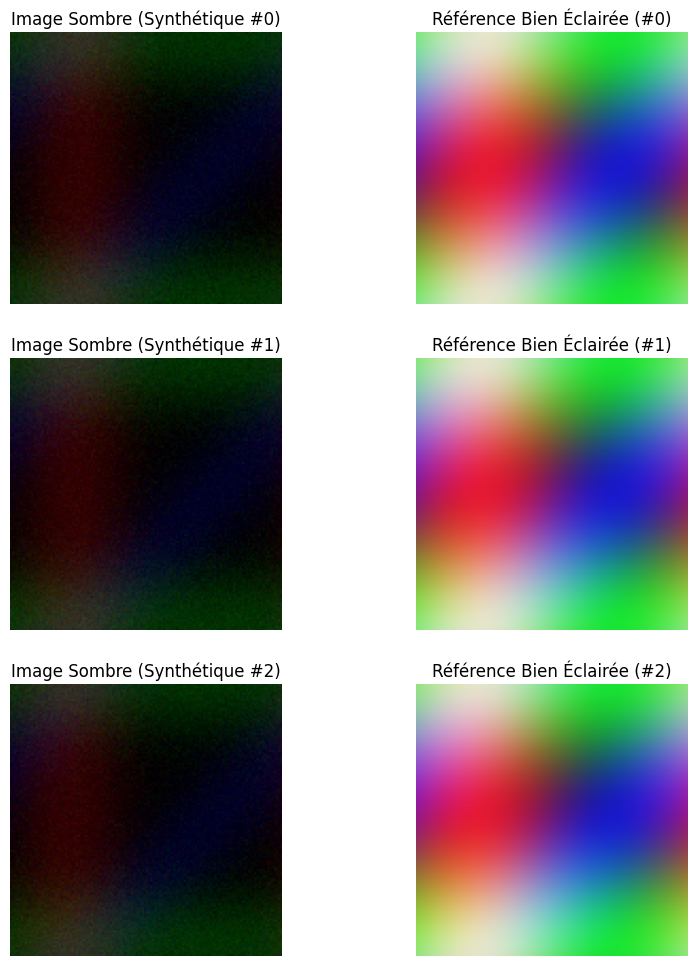

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))
plt.subplots_adjust(wspace=0.1, hspace=0.2)

if demo_ds is not None:
    for i in range(3):
        item = demo_ds[i]
        low = (item["low_orig"].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        norm = (item["normal_orig"].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        axes[i, 0].imshow(low)
        axes[i, 0].set_title(f"Image Sombre (Synthétique #{i})")
        axes[i, 0].axis("off")
        axes[i, 1].imshow(norm)
        axes[i, 1].set_title(f"Référence Bien Éclairée (#{i})")
        axes[i, 1].axis("off")
else:
    for i in range(min(3, len(splits['train']))):
        pair = splits['train'][i]
        with Image.open(pair.low_path) as im_l, Image.open(pair.normal_path) as im_n:
            axes[i, 0].imshow(im_l)
            axes[i, 0].set_title(f"Sombre : {pair.pair_id}")
            axes[i, 0].axis("off")
            axes[i, 1].imshow(im_n)
            axes[i, 1].set_title(f"Référence : {pair.pair_id}")
            axes[i, 1].axis("off")

plt.show()

### 5. Distribution des Classes ExDark

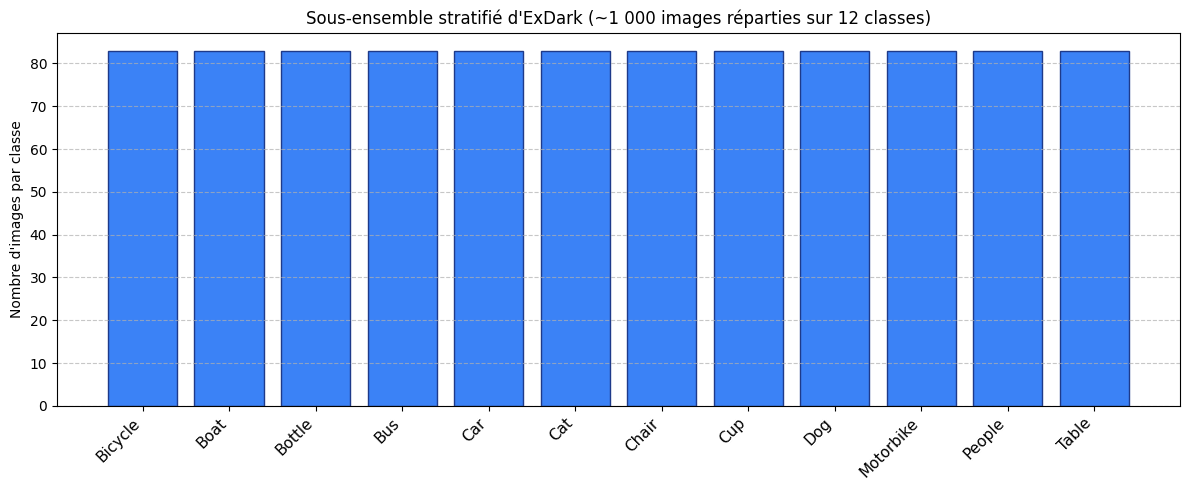

In [5]:
exdark_classes = [
    "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
    "Chair", "Cup", "Dog", "Motorbike", "People", "Table"
]
# Exemple de distribution équilibrée visée pour le sous-ensemble stratifié (environ 83 images par classe)
stratified_counts = [83] * 12

plt.figure(figsize=(12, 5))
plt.bar(exdark_classes, stratified_counts, color="#3b82f6", edgecolor="#1e3a8a")
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.ylabel("Nombre d'images par classe")
plt.title("Sous-ensemble stratifié d'ExDark (~1 000 images réparties sur 12 classes)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 6. Bilan et Conclusions de l'Étape 1
- Les chemins de données sont configurables via `configs/data.yaml`.
- L'intégrité des paires sombre / référence est validée.
- La séparation train/validation/test préserve strictement les 100 paires réelles de test de LOL-v2.
- Les données sont prêtes pour l'étape de prétraitement et de calcul Retinex.